## Module 3: Computational Drug Discovery Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide.

a) Review the example code for modeling semaglutide pharmacokinetics
(semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection
once per week) and Wegovy (daily pill). Replace the portion of the code using an
explicit Euler’s method with use of the more powerful built-in function
scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted
profiles of Ozempic and Wegovy.

b) Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide
(daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how
Cavalitide blood concentration changes over time.

c) Given the higher absorption rate, you hypothesize that you can further optimize the
dosing strategy. Adjust one or two drug or dosing specific parameters until you
achieve a steady state free blood concentration close to 0.5 nM. Plot your result.
What did you change about the dosing strategy and why?

### Task 2a: Replace Euler's Method with "solve_ivp"

The original code manually calculates every small Euler step. solve_ivp solves the same differential equations using an adaptive numerical method. Its t_eval argument specifies when to report the solution; it does not fix the solver’s internal step size.

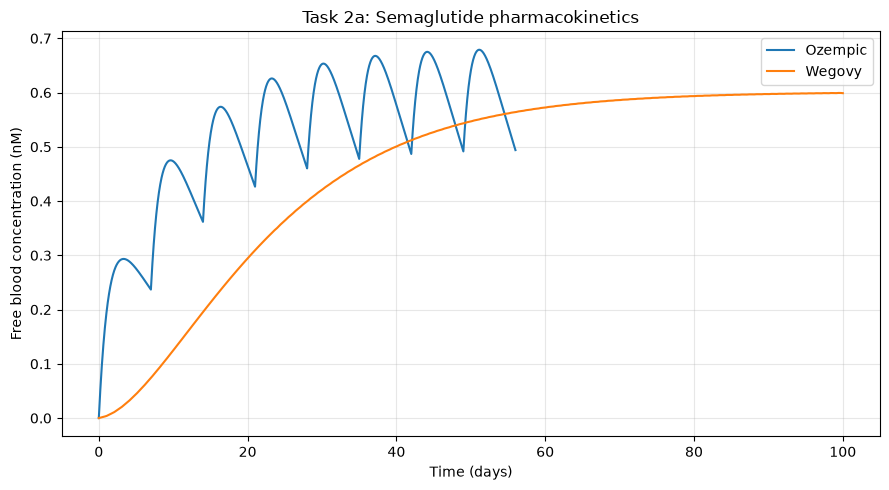

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Shared model parameters from the instructor's code
ke = 0.0039     # elimination rate, 1/h
V = 10.8        # blood distribution volume, L
MW = 4113.6     # molecular weight, g/mol
Ffree = 0.01    # fraction of blood drug that is free

products = {
    "Ozempic": {
        "Favailable": 0.89,
        "ka": 0.029,
        "D": 2.0,
        "interval": 168,
        "n_doses": 8
    },
    "Wegovy": {
        "Favailable": 0.01,
        "ka": 0.0029,
        "D": 25,
        "interval": 24,
        "n_doses": 100
    }
}

def ODEfunc(t, y, ka):
    Asc, Cc = y

    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc

    return [dAsc, dCc]

def simulate(p):
    t_out = []
    Asc_out = []
    Cc_out = []

    # Initially, no drug at the absorption site or in blood
    y = np.array([0.0, 0.0])

    for i in range(p["n_doses"]):
        # Add the next dose to the absorption site
        y[0] += p["Favailable"] * p["D"]

        t0 = i * p["interval"]
        t1 = t0 + p["interval"]

        # Times at which we want the results reported
        t_eval = np.linspace(t0, t1, 241)

        sol = solve_ivp(
            ODEfunc,
            (t0, t1),
            y,
            args=(p["ka"],),
            t_eval=t_eval,
            rtol=1e-8,
            atol=1e-10
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])

        # Preserve the remaining drug for the next dosing interval
        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc = np.concatenate(Asc_out)
    Cc = np.concatenate(Cc_out)

    # Convert total blood concentration from mg/L to nM
    Cc_nM = Cc * 1e6 / MW

    # Only the free fraction is used for the target concentration
    Cfree_nM = Ffree * Cc_nM

    return t, Asc, Cfree_nM

plt.figure(figsize=(9, 5))

for name, p in products.items():
    t, Asc, Cfree = simulate(p)
    plt.plot(t / 24, Cfree, label=name)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2a: Semaglutide pharmacokinetics")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 2b: Add Cavalitide with Faster Absorption

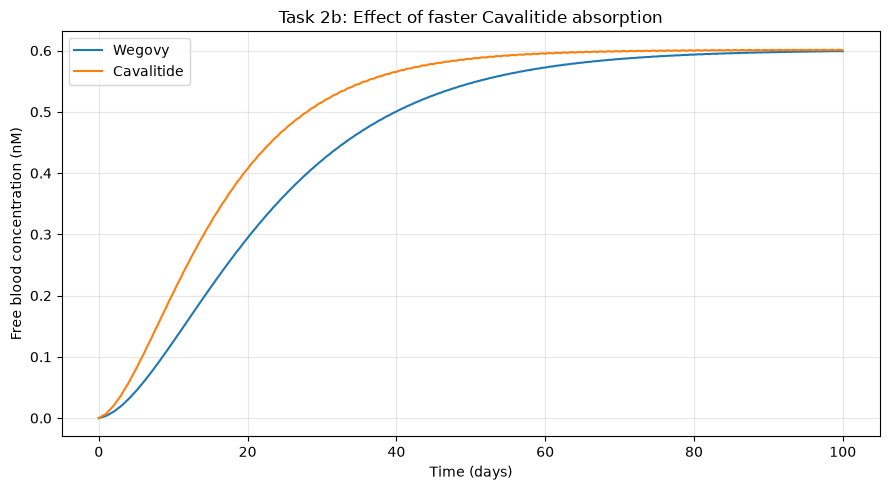

In [2]:
# Assume all other Cavalitide parameters equal the oral example
products["Cavalitide"] = products["Wegovy"].copy()
products["Cavalitide"]["ka"] = 0.006

plt.figure(figsize=(9, 5))

for name in ["Wegovy", "Cavalitide"]:
    t, Asc, Cfree = simulate(products[name])
    plt.plot(t / 24, Cfree, label=name)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2b: Effect of faster Cavalitide absorption")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 2c: Adjust the Code to 

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

TBD

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*